In [81]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.utils import resample
from sklearn.preprocessing import LabelEncoder

Read data set with image already classified

In [82]:
df = pd.read_csv('consolidado_metricas_2016_2025.csv')

Drop not used columns

In [83]:
df.drop('ImagePath', axis=1, inplace=True)
df.drop('Coordinates (x,y)', axis=1, inplace=True)
df.drop('Coordinates', axis=1, inplace=True)

In [84]:
# Apply log to uniformize de area column

df = df[(df['FacadeRoofID'] != 'F?') & (df['AnomalyType'] == 'corrosion')]

# Split Figure description
df['Figura_name'] =  df['AnomalyID'].str.split('#', expand=True)[0]
df['ID_Figura'] =  df['AnomalyID'].str.split('#', expand=True)[1]

# Sort the data
df = df.sort_values(by=['Figura_name', 'ID_Figura', 'data'], ascending=[True,True,True])

# Calculate de diff area
df['Delta_area'] = df.groupby('AnomalyID')['Area (cm2)'].diff()
df['Delta_area'] = df['Delta_area'].fillna(0)

# Lag
df['Delta_area_lag1'] = df.groupby('AnomalyID')['Delta_area'].shift(1).fillna(0)

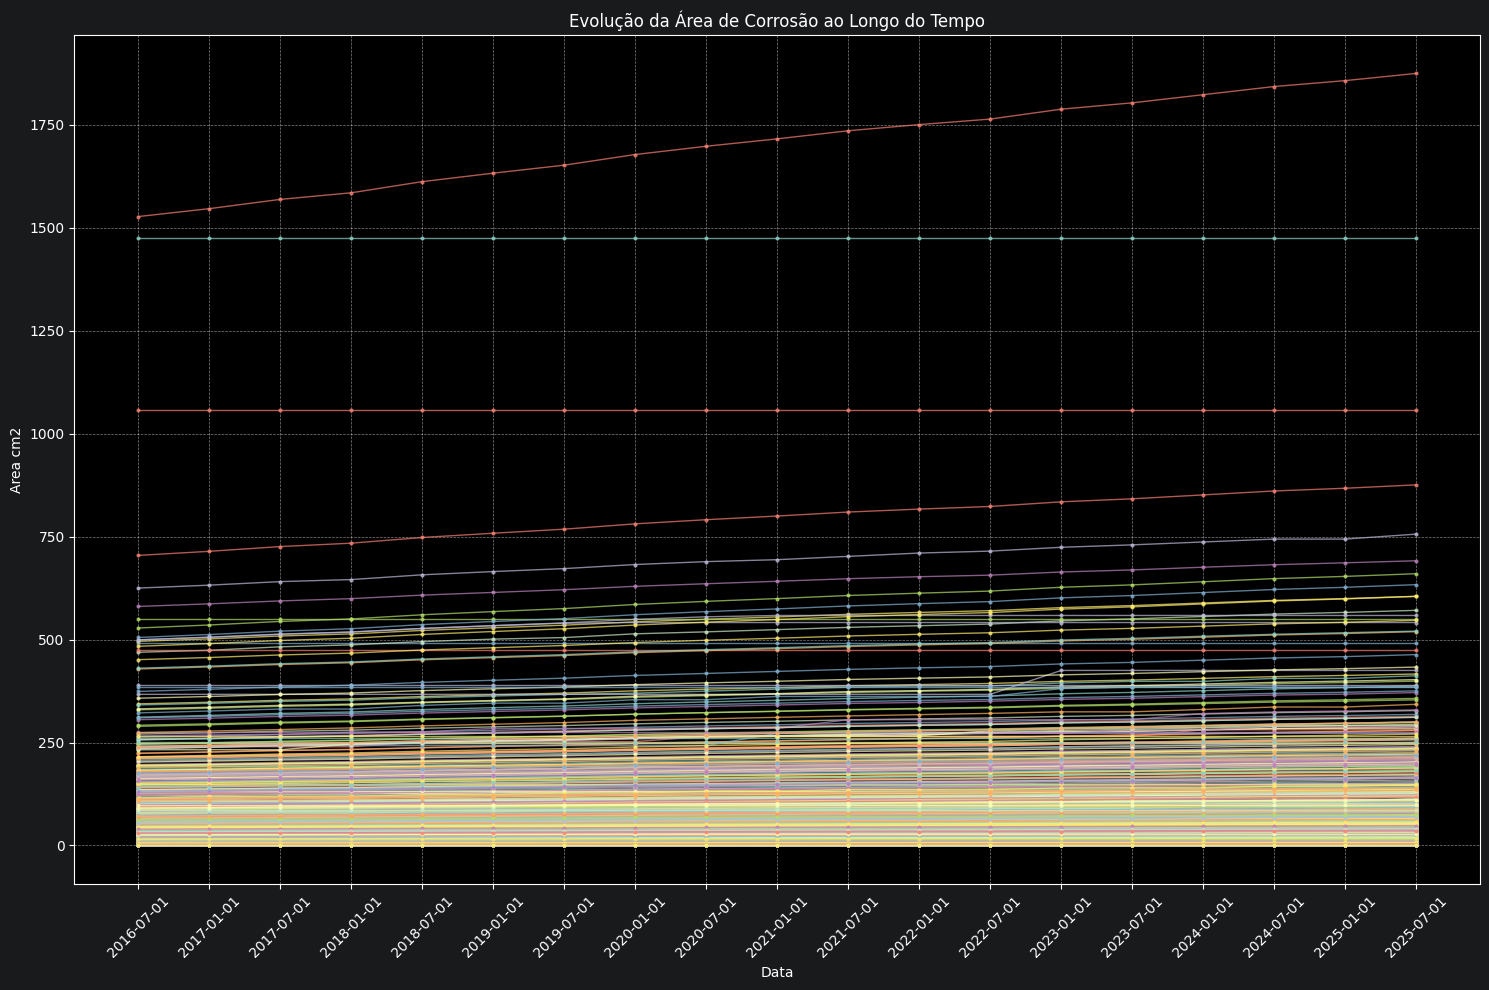

In [85]:
plt.figure(figsize=(15, 10))
plt.style.use('dark_background')

# Agrupar por AnomalyID e desenhar cada linha
for name, group in df.groupby('AnomalyID'):
    plt.plot(group['data'], group['Area (cm2)'], marker='o', markersize=2, linewidth=1, alpha=0.7)

plt.title('Evolução da Área de Corrosão ao Longo do Tempo')
plt.xlabel('Data')
plt.ylabel('Area cm2')
plt.xticks(rotation=45)
plt.grid(True, which='both', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

Make plot

/var/folders/df/ssfk72b12yj9mngh5w92zt3r0000gn/T/ipykernel_1544/2302998779.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x='Faixa_Area', palette='viridis')


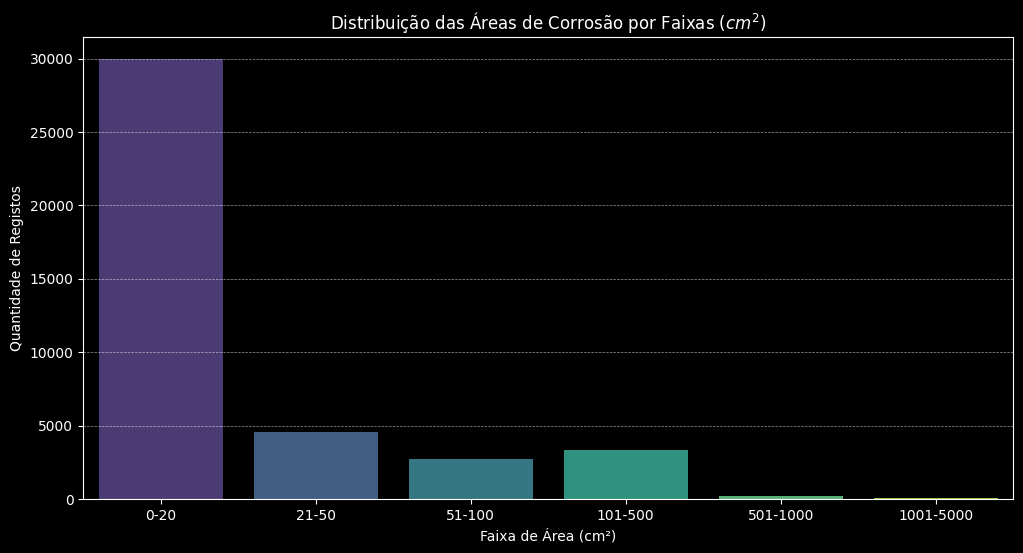

In [86]:
bins = [0, 20, 50, 100, 500, 1000, 5000]
labels = ['0-20', '21-50', '51-100', '101-500', '501-1000', '1001-5000']

# 2. Criar a coluna de categorias
df['Faixa_Area'] = pd.cut(df['Area (cm2)'], bins=bins, labels=labels, include_lowest=True)

# 3. Criar o gráfico de barras
plt.figure(figsize=(12, 6))
ax = sns.countplot(data=df, x='Faixa_Area', palette='viridis')

# Adicionar os valores exatos em cima das barras para clareza
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='baseline', fontsize=10, color='black', xytext=(0, 5),
                textcoords='offset points')

plt.title('Distribuição das Áreas de Corrosão por Faixas ($cm^2$)')
plt.xlabel('Faixa de Área (cm²)')
plt.ylabel('Quantidade de Registos')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()

Make Balance data

In [87]:
def balanceamento_estilo_escada(df):
    bins = [0, 20, 50, 100, 500, 1000, 5000]
    labels = ['0-20', '21-50', '51-100', '101-500', '501-1000', '1001-5000']

    # Definimos alvos específicos para cada barra (baseado na tua imagem)
    alvos = {
        '0-20': 5000,
        '21-50': 4200,
        '51-100': 3500,
        '101-500': 4400,
        '501-1000': 4600,
        '1001-5000': 4000
    }

    df = df.copy()
    df['faixa'] = pd.cut(df['Area (cm2)'], bins=bins, labels=labels, include_lowest=True)

    lista_final = []
    for label in labels:
        df_faixa = df[df['faixa'] == label]
        if len(df_faixa) == 0: continue

        target = alvos[label]

        # Fazemos o sample (com replace se precisar aumentar, sem replace se precisar diminuir)
        df_res = df_faixa.sample(n=target, replace=(len(df_faixa) < target), random_state=42)

        # Adicionamos ruído apenas nas faixas que foram multiplicadas (oversampling)
        if len(df_faixa) < target:
            noise = np.random.normal(1, 0.05, size=target)
            df_res['Area (cm2)'] *= noise

        lista_final.append(df_res)

    return pd.concat(lista_final).sample(frac=1).reset_index(drop=True)

df_novo = balanceamento_estilo_escada(df)

/var/folders/df/ssfk72b12yj9mngh5w92zt3r0000gn/T/ipykernel_1544/129654225.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts.index, y=counts.values, palette='viridis', ax=ax)


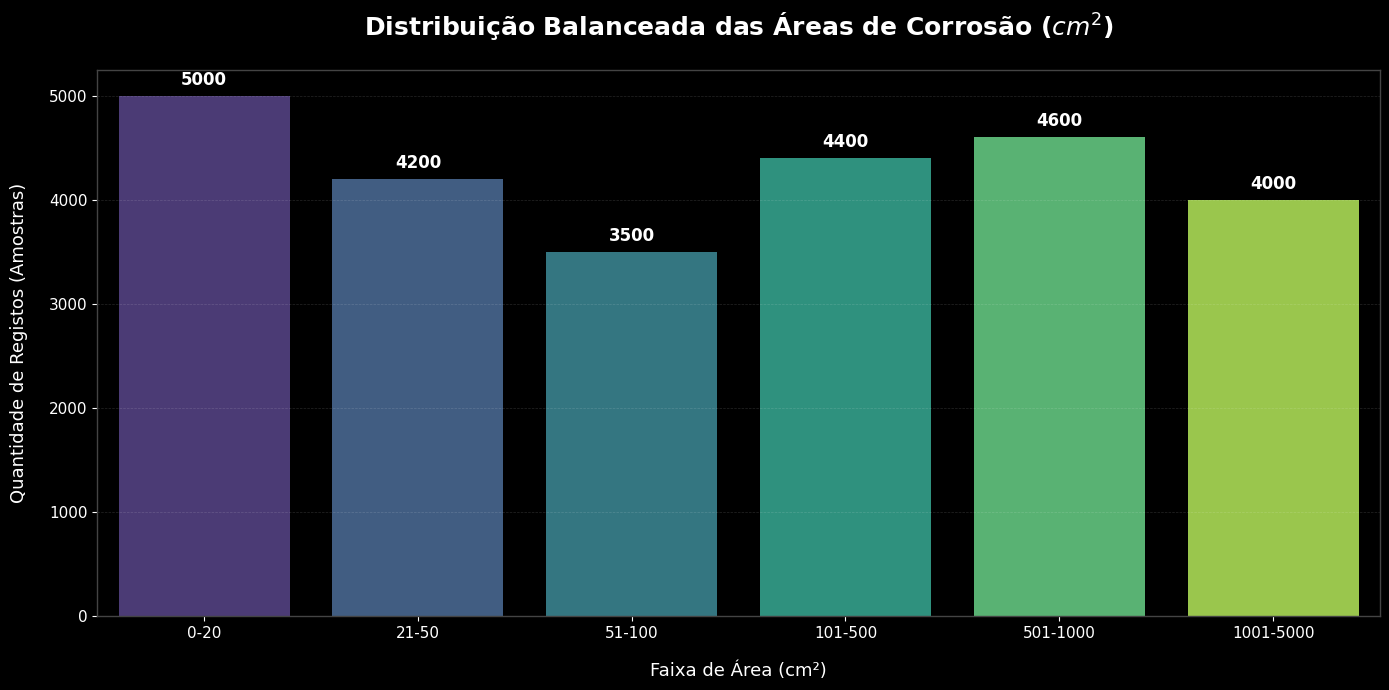

In [88]:
# 1. Setup de cores e estilo
plt.style.use('dark_background')
fig, ax = plt.subplots(figsize=(14, 7), facecolor='#000000') # Fundo preto puro
ax.set_facecolor('#000000')

# 2. Gráfico de barras
# Calculando os valores para o barplot
counts = df_novo['Faixa_Area'].value_counts().reindex(labels)
sns.barplot(x=counts.index, y=counts.values, palette='viridis', ax=ax)

# 3. DESTACAR LEGENDAS E EIXOS
plt.title('Distribuição Balanceada das Áreas de Corrosão ($cm^2$)',
          fontsize=18, pad=25, color='#FFFFFF', fontweight='bold')

plt.xlabel('Faixa de Área (cm²)', fontsize=13, color='#FFFFFF', labelpad=15)
plt.ylabel('Quantidade de Registos (Amostras)', fontsize=13, color='#FFFFFF', labelpad=15)

# Ajustar os 'ticks' (os nomes das faixas e os números do eixo Y)
ax.tick_params(axis='x', colors='#FFFFFF', labelsize=11)
ax.tick_params(axis='y', colors='#FFFFFF', labelsize=11)

# 4. DESTACAR VALORES NO TOPO DAS BARRAS
for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'{int(height)}',
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='baseline',
                fontsize=12, color='#FFFFFF', # Branco puro para os números
                fontweight='bold',
                xytext=(0, 8), # Sobe um pouco mais o texto para não encostar na barra
                textcoords='offset points')

# 5. Ajuste fino das bordas e grade
for spine in ax.spines.values():
    spine.set_edgecolor('#444444') # Borda cinza escura muito sutil
    spine.set_linewidth(1)

plt.grid(axis='y', linestyle='--', alpha=0.15, color='#FFFFFF') # Grade bem suave

plt.tight_layout()
plt.show()

In [89]:
df_novo['ID_Unico'] = df_novo['Figura_name'].astype(str) + "#" + df_novo['ID_Figura'].astype(str)
df_novo['data'] = pd.to_datetime(df_novo['data'])

datas_full = pd.date_range(start='2016-01-01', end='2024-07-01', freq='6MS')

def fills_gaps(grupo):
    grupo = grupo.groupby('data').agg({
        'Area (cm2)': 'mean',
        'FacadeRoofID': 'first',
        'AnomalyType': 'first',
        'Figura_name': 'first',
        'ID_Figura': 'first'
    })

    grupo = grupo.reindex(datas_full)

    grupo['Area (cm2)'] = grupo['Area (cm2)'].interpolate(method='linear', limit_direction='both')
    grupo = grupo.ffill().bfill()

    return grupo.reset_index().rename(columns={'index': 'data'})

df_final = df_novo.groupby('ID_Unico', group_keys=False).apply(fills_gaps).reset_index(drop=True)

In [90]:
def balance_gaps(df, target_pequenas=7000, target_grandes=4500):
    bins = [0, 20, 50, 100, 500, 1000, 5000]
    labels = ['0-20', '21-50', '51-100', '101-500', '501-1000', '1001-5000']

    df = df.copy()

    df['Faixa_Area'] = pd.cut(df['Area (cm2)'], bins=bins, labels=labels, include_lowest=True)

    lista_final = []

    for label in labels:
        df_faixa = df[df['Faixa_Area'] == label]
        if len(df_faixa) == 0:
            continue

        if label == '0-20':
            df_res = df_faixa.sample(n=min(len(df_faixa), target_pequenas), random_state=42)

        elif label in ['501-1000', '1001-5000']:
            df_res = df_faixa.sample(n=target_grandes, replace=True, random_state=42)

            noise = np.random.normal(1, 0.06, size=len(df_res))
            df_res['Area (cm2)'] *= noise
        else:
            n_samples = 4500 if len(df_faixa) < 4500 else min(len(df_faixa), 5000)
            df_res = df_faixa.sample(n=n_samples, replace=(len(df_faixa) < n_samples), random_state=42)

        lista_final.append(df_res)

    return pd.concat(lista_final).sample(frac=1).reset_index(drop=True)

df_balanceado_final = balance_gaps(df_final)

/var/folders/df/ssfk72b12yj9mngh5w92zt3r0000gn/T/ipykernel_1544/1410406985.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts.index, y=counts.values, palette='viridis', ax=ax, edgecolor='white', linewidth=1)


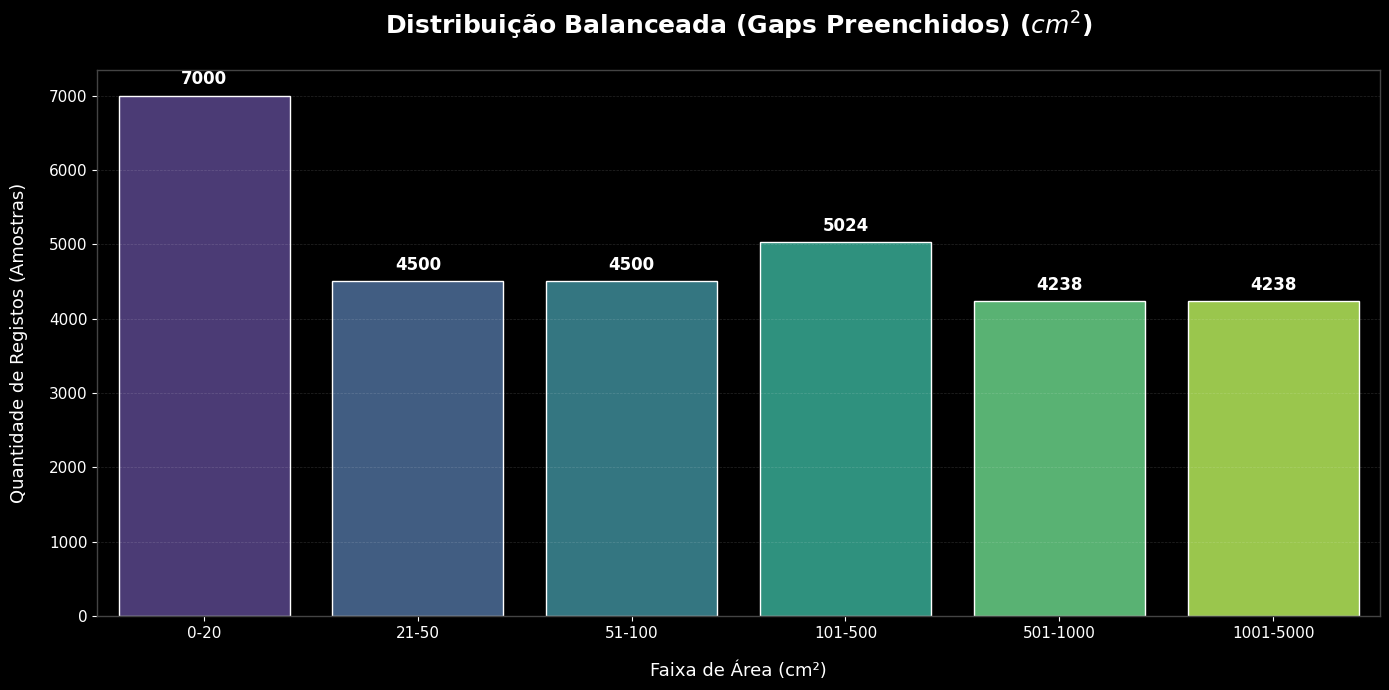

In [91]:
bins = [0, 20, 50, 100, 500, 1000, 5000]
labels = ['0-20', '21-50', '51-100', '101-500', '501-1000', '1001-5000']
df_balanceado_final['Faixa_Area'] = pd.cut(df_balanceado_final['Area (cm2)'], bins=bins, labels=labels, include_lowest=True)

plt.style.use('dark_background')
fig, ax = plt.subplots(figsize=(14, 7), facecolor='#000000')
ax.set_facecolor('#000000')

counts = df_balanceado_final['Faixa_Area'].value_counts().reindex(labels)

sns.barplot(x=counts.index, y=counts.values, palette='viridis', ax=ax, edgecolor='white', linewidth=1)

plt.title('Distribuição Balanceada (Gaps Preenchidos) ($cm^2$)',
          fontsize=18, pad=25, color='#FFFFFF', fontweight='bold')

plt.xlabel('Faixa de Área (cm²)', fontsize=13, color='#FFFFFF', labelpad=15)
plt.ylabel('Quantidade de Registos (Amostras)', fontsize=13, color='#FFFFFF', labelpad=15)

ax.tick_params(axis='x', colors='#FFFFFF', labelsize=11)
ax.tick_params(axis='y', colors='#FFFFFF', labelsize=11)

for p in ax.patches:
    height = p.get_height()
    if height > 0: # Só desenha se houver valor
        ax.annotate(f'{int(height)}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='baseline',
                    fontsize=12, color='#FFFFFF',
                    fontweight='bold',
                    xytext=(0, 8),
                    textcoords='offset points')

for spine in ax.spines.values():
    spine.set_edgecolor('#444444')
    spine.set_linewidth(1)

plt.grid(axis='y', linestyle='--', alpha=0.15, color='#FFFFFF')

plt.tight_layout()
plt.show()

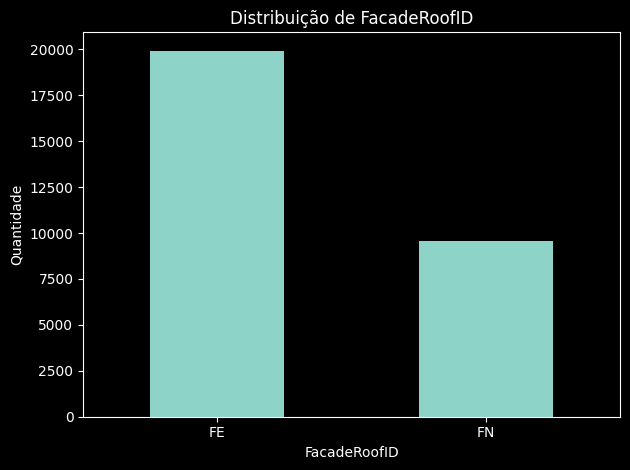

In [92]:
counts = df_balanceado_final["FacadeRoofID"].value_counts()

plt.figure()
counts.plot(kind='bar')
plt.xlabel("FacadeRoofID")
plt.ylabel("Quantidade")
plt.title("Distribuição de FacadeRoofID")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [93]:
df_majority = df_balanceado_final[df_balanceado_final["FacadeRoofID"] == "FE"]
df_minority = df_balanceado_final[df_balanceado_final["FacadeRoofID"] == "FN"]

# fazer oversampling da classe minoritária
df_minority_upsampled = resample(
    df_minority,
    replace=True,                 # permite repetição
    n_samples=len(df_majority),   # igualar ao tamanho da maior
    random_state=42
)

# juntar tudo
df_balanced = pd.concat([df_majority, df_minority_upsampled])

# baralhar (importante!)
df_balanced = df_balanced.sample(frac=1, random_state=42).reset_index(drop=True)

print(df_balanced.head())

        data  Area (cm2) FacadeRoofID AnomalyType  Figura_name ID_Figura  \
0 2017-01-01  460.077183           FE   corrosion  Figura_1081        28   
1 2016-07-01  445.707978           FE   corrosion  Figura_1081        28   
2 2018-07-01  165.213572           FN   corrosion   Figura_220         0   
3 2022-07-01    0.905500           FN   corrosion   Figura_692        20   
4 2021-01-01   28.697500           FN   corrosion   Figura_500         3   

  Faixa_Area  
0    101-500  
1    101-500  
2    101-500  
3       0-20  
4      21-50  


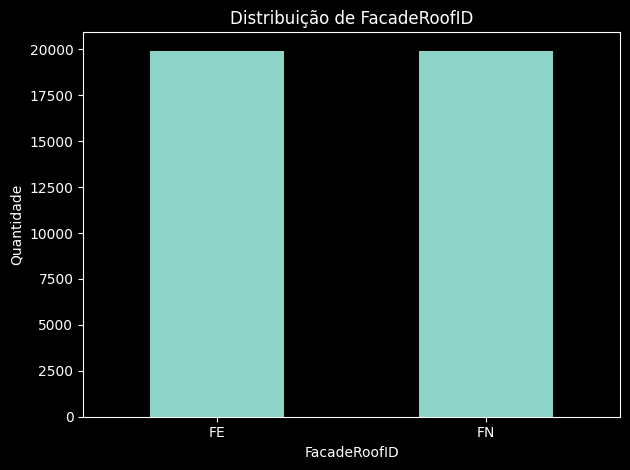

In [94]:
counts = df_balanced["FacadeRoofID"].value_counts()

plt.figure()
counts.plot(kind='bar')
plt.xlabel("FacadeRoofID")
plt.ylabel("Quantidade")
plt.title("Distribuição de FacadeRoofID")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

/var/folders/df/ssfk72b12yj9mngh5w92zt3r0000gn/T/ipykernel_1544/2270039053.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts.index, y=counts.values, palette='viridis', ax=ax, edgecolor='white', linewidth=1)


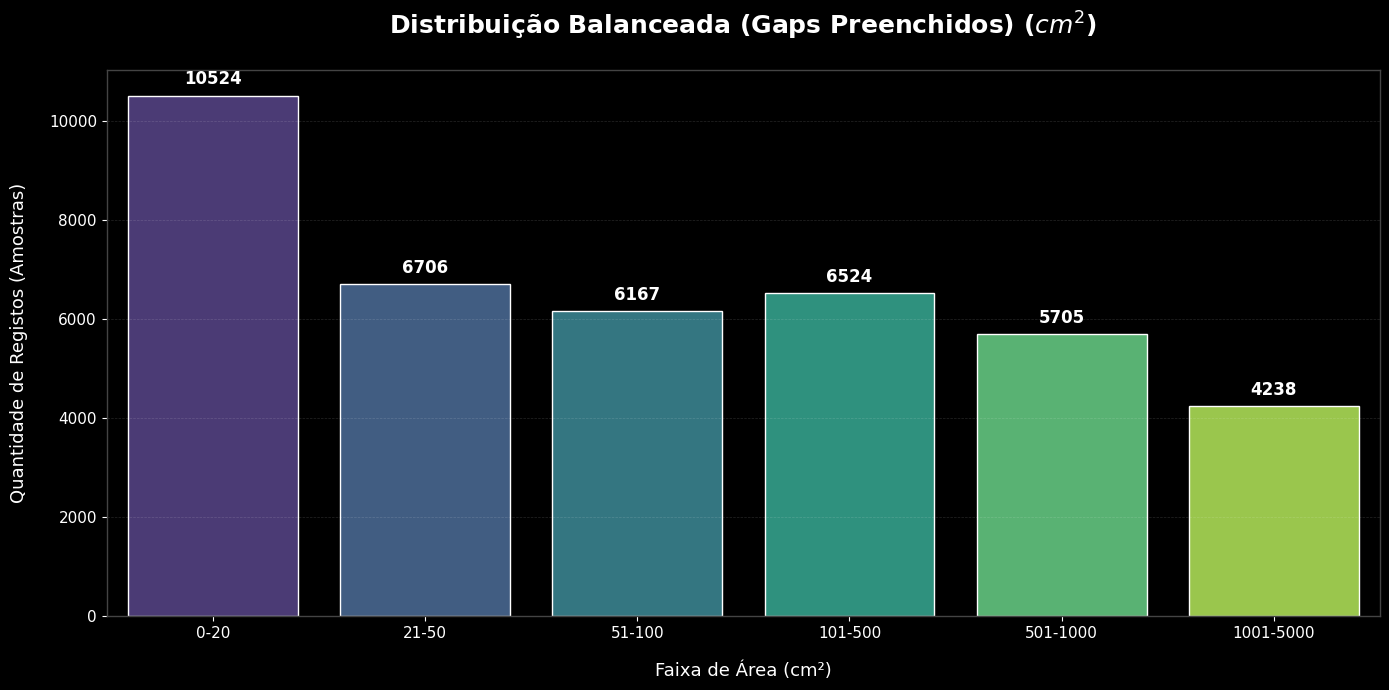

In [95]:
bins = [0, 20, 50, 100, 500, 1000, 5000]
labels = ['0-20', '21-50', '51-100', '101-500', '501-1000', '1001-5000']
df_balanced['Faixa_Area'] = pd.cut(df_balanced['Area (cm2)'], bins=bins, labels=labels, include_lowest=True)

plt.style.use('dark_background')
fig, ax = plt.subplots(figsize=(14, 7), facecolor='#000000')
ax.set_facecolor('#000000')

counts = df_balanced['Faixa_Area'].value_counts().reindex(labels)

sns.barplot(x=counts.index, y=counts.values, palette='viridis', ax=ax, edgecolor='white', linewidth=1)

plt.title('Distribuição Balanceada (Gaps Preenchidos) ($cm^2$)',
          fontsize=18, pad=25, color='#FFFFFF', fontweight='bold')

plt.xlabel('Faixa de Área (cm²)', fontsize=13, color='#FFFFFF', labelpad=15)
plt.ylabel('Quantidade de Registos (Amostras)', fontsize=13, color='#FFFFFF', labelpad=15)

ax.tick_params(axis='x', colors='#FFFFFF', labelsize=11)
ax.tick_params(axis='y', colors='#FFFFFF', labelsize=11)

for p in ax.patches:
    height = p.get_height()
    if height > 0: # Só desenha se houver valor
        ax.annotate(f'{int(height)}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='baseline',
                    fontsize=12, color='#FFFFFF',
                    fontweight='bold',
                    xytext=(0, 8),
                    textcoords='offset points')

for spine in ax.spines.values():
    spine.set_edgecolor('#444444')
    spine.set_linewidth(1)

plt.grid(axis='y', linestyle='--', alpha=0.15, color='#FFFFFF')

plt.tight_layout()
plt.show()

In [96]:
bins = [0, 20, 50, 100, 500, 1000, 5000]
labels = ["0-20", "21-50", "51-100", "101-500", "501-1000", "1001-5000"]

df_balanced["area_bin"] = pd.cut(df_balanced["Area (cm2)"], bins=bins, labels=labels)

max_size = df_balanced.groupby(["FacadeRoofID", "Faixa_Area"]).size().max()

balanced_dfs = []

for (facade, area_bin), group in df.groupby(["FacadeRoofID", "Faixa_Area"]):

    if len(group) < max_size:
        group_resampled = resample(
            group,
            replace=True,
            n_samples=max_size,
            random_state=42
        )
    else:
        group_resampled = group

    balanced_dfs.append(group_resampled)

df_balanced = pd.concat(balanced_dfs).sample(frac=1, random_state=42)

print(df_balanced.head())

             data       AnomalyID FacadeRoofID AnomalyType  Area (cm2)  \
13819  2018-07-01    Figura_500#3           FN   corrosion     27.2796   
48248  2024-07-01   Figura_946#16           FE   corrosion     33.4003   
27335  2021-01-01    Figura_978#5           FE   corrosion     14.6654   
790    2016-07-01  Figura_1051#15           FE   corrosion    159.8703   
19962  2019-07-01   Figura_1096#7           FE   corrosion    187.1790   

      SimulationDate  Surface3DArea_cm2  Added3DArea_cm2  SurfaceVertexCount  \
13819     2018-07-01            27.2796           0.0000                19.0   
48248     2024-07-01            33.4003           0.3692                84.0   
27335     2021-01-01            14.6654           0.0000               144.0   
790       2016-07-01           159.8703           3.4054                61.0   
19962     2019-07-01           187.1790           2.1176               121.0   

       SurfaceNormalX  ...  MeanTransitionUsedDeg  MaxTransitionUsedDeg  \

In [97]:
le = LabelEncoder()
cols_para_transformar = ['Figura_name', 'FacadeRoofID']

for col in cols_para_transformar:
    # Criamos o nome da nova coluna (ex: Figura_name_encoded)
    df_balanced[f'{col}_encoded'] = le.fit_transform(df_balanced[col])

df_balanced = df_balanced.sort_values(by=['Figura_name', 'ID_Figura', 'data'], ascending=[True,True,True])

print(df_balanced.head())

             data   AnomalyID FacadeRoofID AnomalyType  Area (cm2)  \
953    2016-07-01  Figura_1#0           FN   corrosion      4.7349   
5704   2017-01-01  Figura_1#0           FN   corrosion      4.8075   
8200   2017-07-01  Figura_1#0           FN   corrosion      4.8801   
11053  2018-01-01  Figura_1#0           FN   corrosion      4.9346   
12838  2018-07-01  Figura_1#0           FN   corrosion      5.0253   

      SimulationDate  Surface3DArea_cm2  Added3DArea_cm2  SurfaceVertexCount  \
953       2016-07-01             4.7349           0.1089                20.0   
5704      2017-01-01             4.8075           0.0726                24.0   
8200      2017-07-01             4.8801           0.0726                28.0   
11053     2018-01-01             4.9346           0.0545                31.0   
12838     2018-07-01             5.0253           0.0908                36.0   

       SurfaceNormalX  ...  SurfacePatchVertices  SurfaceSpacing_m  \
953         -0.224089  ...  

In [98]:
#corr_matrix = df_balanced.corr()

# 2. Configurar o gráfico
#plt.figure(figsize=(12, 8))
#sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)

# 3. Exibir
#plt.title("Matriz de Correlação das Variáveis")
#plt.show()

In [99]:
df_balanced.to_csv('dataset_area/Image_Dataset.csv', index=False)

PROCESS DATA FOR TEST MODEL

In [100]:
# Ler o ficheiro CSV original
df_test = pd.read_csv("obra/2026/01_01_2026/pred/ps/metricas_anomalias_faces_malha_2026-01-01_ambiente_3D_HIBRIDO.csv")

# Remover colunas desnecessárias (errors='ignore' evita erros caso alguma não exista)
df_test.drop('ImagePath', axis=1, inplace=True, errors='ignore')
df_test.drop('Coordinates (x,y)', axis=1, inplace=True, errors='ignore')
df_test.drop('Coordinates', axis=1, inplace=True, errors='ignore')

# Filtrar IDs válidos e tipo de anomalia (corrosion)
df_test = df_test[(df_test['FacadeRoofID'] != 'F?') & (df_test['AnomalyType'] == 'corrosion')]

# --- FILTRO ADICIONADO: Garantir que apenas entram dados de 2026 ---
df_test['data'] = pd.to_datetime(df_test['data'])
df_test = df_test[df_test['data'].dt.year == 2026]
# -----------------------------------------------------------------

# Split Figure description
df_test['Figura_name'] = df_test['AnomalyID'].str.split('#', expand=True)[0]
df_test['ID_Figura'] = df_test['AnomalyID'].str.split('#', expand=True)[1]

# Sort the data
df_test = df_test.sort_values(by=['Figura_name', 'ID_Figura', 'data'], ascending=[True, True, True])

# Calculate de diff area
df_test['Delta_area'] = df_test.groupby('AnomalyID')['Area (cm2)'].diff()
df_test['Delta_area'] = df_test['Delta_area'].fillna(0)

# Lag
df_test['Delta_area_lag1'] = df_test.groupby('AnomalyID')['Delta_area'].shift(1).fillna(0)

# Guardar o resultado final limpo
df_test.to_csv('dataset_area/Image_Dataset_Test.csv', index=False)